# Decision Tree
This notebook trains a Decision Tree to predict gallstone disease, using features from the data exploration.

### Type of machine learning:
Binary classification: 0 = gallstones, 1 = no gallstones.

### Model justification:
A Decision Tree learns simple rules from feature values. It is easy to visualize, but can overfit.


### Research question:
How well does the tree predict gallstones, and does tuning improve it?

### Splitting criteria:
The initial tree uses Gini impurity:

$$
G = 1 - (p_0^2 + p_1^2)
$$

A lower value means less mixed classes. Tuning also tests entropy.

## Training:

Data is loaded through data_loader.py, then cleaned using cells from the data part notebook. 
We keep its seven features and 80/20 stratified split (seed 37). The tree uses seed 77.
The selected features have no missing values. A tree does not need scaling.

### Initial install of libraries/packages
Uncomment if needed.

In [1]:
#%pip install -q pandas numpy scikit-learn matplotlib nbformat # installerer pakkene i notebookens Python-miljø

### Import library

In [ ]:
from __future__ import annotations # lar typebeskrivelsene brukes uten å påvirke kjøringen.
from typing import Any # beskriver data som hentes dynamisk.
import json # leser kildekoden i datanotebooken uten ekstra notebook-pakker
from pathlib import Path # lager relative filstier i repoet
import pandas as pd # leser CSV-filen og jobber med tabeller
import numpy as np # lager tallrekker til grafene
import matplotlib.pyplot as plt # tegner grafer
from IPython.utils.capture import capture_output # skjuler ekstra utskrift fra datanotebooken
from sklearn import tree, model_selection as ms, metrics, compose, pipeline # henter modell- og evalueringsverktøy
from sklearn.base import clone # kopierer modell og scaler uten å ta med tidligere tilpasning
from sklearn.preprocessing import StandardScaler # beskriver skaleringen fra datanotebooken
from matplotlib.container import BarContainer # gjenkjenner stolpene som kan få verdietiketter
from numpy.typing import NDArray # beskriver tallrekkene med modellens svar og sannsynligheter

### Plot settings and class labels

In [21]:
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11}) # velger figur- og skriftstørrelse
COLORS = ["#2878A7", "#6C7A35", "#CB762D"] # velger fargene til grafene
CLASS_NAMES = ["Gallstones (0)", "No gallstones (1)"] # gir navn til klasse 0 og 1

### Preprocessing from data notebook

In [23]:
from src.data_loader import load_data # henter datalasteren fra src-mappen

DATA_PATH = Path("dataset-uci.csv") # CSV-filen ligger på samme nivå som modellfilen.
DATA_NOTEBOOK = Path("Data_part1_final.ipynb") # datanotebooken ligger også på samme nivå.

source = json.loads(DATA_NOTEBOOK.read_text(encoding="utf-8")) # leser cellene i datanotebooken.
source_data: dict[str, Any] = {
    "pd": pd, 
    "np": np, 
    "display": display,
    "galle_set": load_data(DATA_PATH, "Gallstone Status")
    }

cell_numbers = [33, 35, 36, 52, 53, 56, 58, 61, 63, 67, 69, 71] # Velger nødvendige dataceller, telt fra null

with capture_output(): # skjuler datanotebookens store tabeller og ekstra utskrift
    for i in cell_numbers: # går gjennom datavask og forbehandling i opprinnelig rekkefølge
        exec("".join(source["cells"][i]["source"]), source_data) # kjører hver celle med dataene fra datalasteren

### Variables from data notebook

In [24]:
galle_set = source_data["galle_set"] # renset datasett
continous_features = source_data["continous_features"] #  numeriske variabler som undersøkes og skaleres
outlier_results = source_data["outlier_results"] # listen med resultater fra IQR-analysen
outlier_summary = source_data["outlier_summary"] # tabellen som oppsummerer uteliggere per variabel
suspicious_rows = source_data["suspicious_rows"] # mistenkelige rader fra undersøkelsen før erstatning
X = source_data["X"] # alle forklaringsvariablene, uten "Gallstone Status"
y = source_data["y"] # målvariabelen "Gallstone Status"
X_train = source_data["X_train"] # alle forklaringsvariablene for de 80 prosentene som brukes til trening
X_test = source_data["X_test"] # alle forklaringsvariablene for de 20 prosentene som brukes til test
y_train = source_data["y_train"] # fasit for treningspasientene
y_test = source_data["y_test"] # fasit for testpasientene
scaler = source_data["scaler"] # standardScaler tilpasset kontinuerlige variabler i hele treningssettet
correlation = source_data["correlation"] # korrelasjonen mellom  numeriske forklaringsvariabel og målvariabel
top_features = source_data["top_features"] # de ti variablene med høyest absolutt korrelasjon med målvariabelen
selected_features = list(source_data["selected_features"]) # en lokal kopi av de sju variablene valgt til modellering
feature_correlation = source_data["feature_correlation"] # korrelasjonsmatrisen mellom de ti variablene i top_features
print("Prepared data:", galle_set.shape, "Suspicious rows:", len(suspicious_rows)) # viser omfanget av datagrunnlaget
outlier_summary[["Feature", "Number of outliers"]].head(5) # viser en kort oppsummering av IQR-analysen

Prepared data: (319, 39) Suspicious rows: 8


,Feature,Number of outliers
28,C-Reactive Protein (CRP),34
24,Alanin Aminotransferaz (ALT),27
18,Glucose,25
23,Aspartat Aminotransferaz (AST),23
22,Triglyceride,20


### Models input from existing split

In [ ]:
model_continous = [name for name in selected_features if name in continous_features] # velger kontinuerlige modellvariabler
X_train_model = galle_set.loc[X_train.index, selected_features] # samme treningsrader og sju variabler, før skalering
X_test_model = galle_set.loc[X_test.index, selected_features] # samme testrader og sju variabler, før skalering
cv = ms.StratifiedKFold(n_splits=5, shuffle=True, random_state=37) # lager fem faste valideringsfold
print("Training patients:", len(X_train_model), "Test patients:", len(X_test_model)) # viser størrelsen på modellsettene

Training patients: 255 Test patients: 64


### Initial tree and max depth = 3
Compare average accuracy over five training folds. Test data is kept for evaluation.

In [19]:
scale_features = compose.ColumnTransformer( # Skalerer bare de kontinuerlige modellvariablene.
    [("continuous", clone(scaler), model_continous)], # Bruker en ny kopi av StandardScaler fra datakilden.
    remainder="passthrough", verbose_feature_names_out=False # Beholder binære variabler uten skalering.
) # Avslutter oppsettet for skalering.
decision_tree = pipeline.Pipeline([ # Kobler skalering og klassifikasjon til én modell.
    ("scale", scale_features), # Tilpasser skalering bare på dataene modellen trenes med.
    ("tree", tree.DecisionTreeClassifier(random_state=77)) # Lager starttreet med fast seed.
]) # Avslutter modellen.
small_tree: pipeline.Pipeline = clone(decision_tree).set_params(tree__max_depth=3) # Lager samme modell med treets maksdybde satt til 3.
for name, model in [("Initial tree", decision_tree), ("Depth 3 tree", small_tree)]: # Tester begge trærne.
    scores = ms.cross_val_score(model, X_train_model, y_train, cv=cv, scoring="accuracy") # Måler fem CV-resultater.
    print(f"{name}: CV accuracy = {scores.mean():.3f}") # Viser gjennomsnittlig nøyaktighet.

Initial tree: CV accuracy = 0.722
Depth 3 tree: CV accuracy = 0.678


### Optimizing tree
GridSearchCV tests 432 combinations on training data and keeps the best average accuracy. It tests splitting rules, tree size and pruning.

In [7]:
param_grid = { # samler innstillingene søket skal prøve
    "criterion": ["gini", "entropy"], # prøver to måter å velge delinger på
    "max_depth": [2, 3, 4, 5, 6, None], # prøver ulike dybder; None betyr ingen grense
    "min_samples_split": [2, 10, 20], # minste antall pasienter for å dele en node
    "min_samples_leaf": [1, 3, 5, 10], # minste antall pasienter i en sluttnode
    "ccp_alpha": [0.0, 0.005, 0.02] # prøver ulike grader av beskjæring
}
grid_search = ms.GridSearchCV(decision_tree, param_grid, cv=cv, # setter opp søket med fem fold
                              scoring="accuracy", error_score="raise") # velger etter nøyaktighet og stopper ved feil
grid_search.fit(X_train, y_train) # tester kombinasjonene bare på treningsdata
best_tree = grid_search.best_estimator_ # henter modellen med best gjennomsnittlig CV-resultat
print("Best parameters:", grid_search.best_params_) # viser innstillingene søket valgte
print(f"Best CV accuracy: {grid_search.best_score_:.3f}") # viser modellens beste CV-gjennomsnitt

Best parameters: {'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.741


### Calculate training and testing results
All three trees use the same test set. 
- Recall measures how many gallstone cases are found
- ROC-AUC measures how well the model separates the groups.

In [8]:
models = {"Initial tree": decision_tree, "Depth 3 tree": small_tree, "Tuned tree": best_tree} # samler trærne
predictions = {} # lagring av modellens svar for testpasientene
probabilities = {} # lagring av  sannsynligheten for gallestein
rows = [] # lagring av en enkel resultatlinje per modell
for name, model in models.items(): # går gjennom alle tre modellene
    model.fit(X_train, y_train) # trener modellen på treningssettet
    predictions[name] = model.predict(X_test) # predikerer klassen til testpasientene
    probabilities[name] = model.predict_proba(X_test)[:, 0] # henter sannsynligheten for klasse 0: gallestein
    rows.append({ # legger modellens resultater i tabellen
        "Model": name, "Train accuracy": model.score(X_train, y_train), # lagrer navn og treningsnøyaktighet
        "Test accuracy": model.score(X_test, y_test), # lagrer nøyaktigheten på testsettet
        "Gallstone recall": metrics.recall_score(y_test, predictions[name], pos_label=0), # andel gallesteinstilfeller funnet
        "ROC-AUC": metrics.roc_auc_score(y_test == 0, probabilities[name]) # måler hvor godt gruppene skilles
    })
results = pd.DataFrame(rows).set_index("Model") # lager en tabell med modellnavn som radnavn
print(metrics.classification_report(y_test, predictions["Tuned tree"], # viser detaljer for det tunede treet
                                    labels=[0, 1], target_names=CLASS_NAMES, digits=3)) # bruker riktige klassenavn
results.round(3) # viser resultatene med tre desimaler

                   precision    recall  f1-score   support

   Gallstones (0)      0.786     0.688     0.733        32
No gallstones (1)      0.722     0.812     0.765        32

         accuracy                          0.750        64
        macro avg      0.754     0.750     0.749        64
     weighted avg      0.754     0.750     0.749        64



,Train accuracy,Test accuracy,Gallstone recall,ROC-AUC
Model,,,,
Initial tree,1.000,0.672,0.562,0.672
Depth 3 tree,0.769,0.797,0.719,0.891
Tuned tree,1.000,0.750,0.688,0.750


### Training and test accuracy

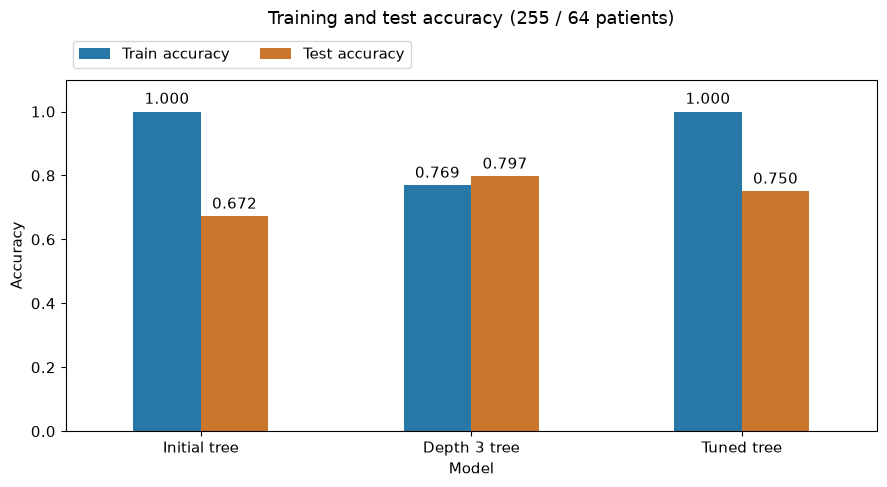

In [13]:
ax = results[["Train accuracy", "Test accuracy"]].plot.bar( # sammenligner trenings- og testnøyaktighet
    color=[COLORS[0], COLORS[2]], rot=0, ylim=(0, 1.1) # bruker to farger, rette navn og en skala fra null
)
ax.set(xlabel="Model", ylabel="Accuracy") # gir navn til aksene
ax.set_title("Training and test accuracy (255 / 64 patients)", pad=40) # legger til tittel og plass over grafen
for bars in ax.containers: # går gjennom begge grupper med stolper
    ax.bar_label(bars, fmt="%.3f", padding=3) # skriver resultatet over hver stolpe
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncols=2) # plasserer fargeforklaringen over grafen
plt.tight_layout() # tilpasser avstanden slik at teksten får plass
plt.show() # viser grafen

### Confusion matrix

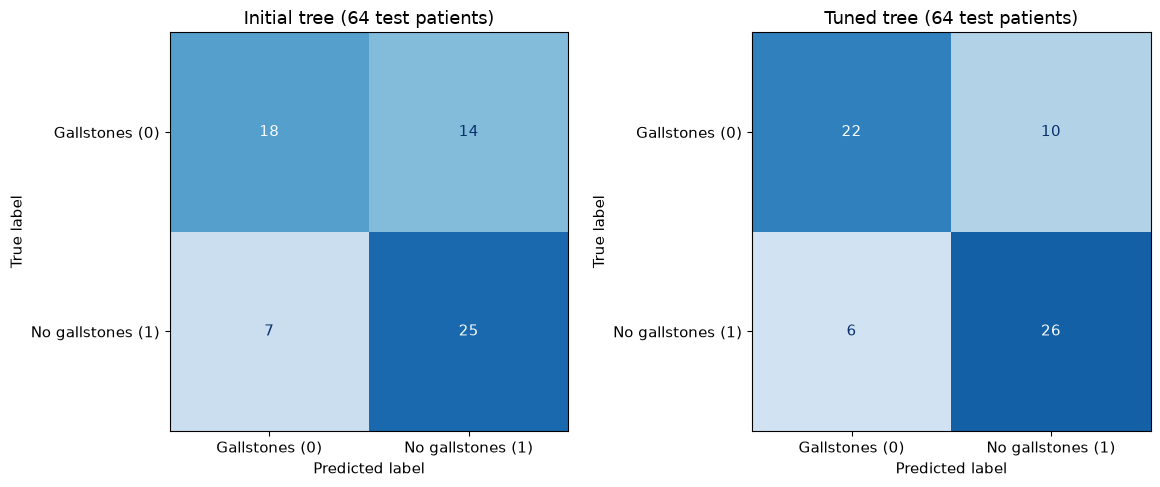

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) # lager to grafer ved siden av hverandre
for ax, name in zip(axes, ["Initial tree", "Tuned tree"]): # velger ett tre til hver graf
    metrics.ConfusionMatrixDisplay.from_predictions( # sammenligner fasit med modellens svar
        y_test, predictions[name], labels=[0, 1], display_labels=CLASS_NAMES, # bruker samme klasserekkefølge
        ax=ax, cmap="Blues", colorbar=False, # tegner på riktig plass med blå farger
        im_kw={"vmin": 0, "vmax": y_test.value_counts().max()} # bruker lik fargeskala i begge grafer
    )
    ax.set_title(f"{name} (64 test patients)") # viser modellnavn og antall testpasienter
plt.tight_layout() # sørger for at navn og akser får plass
plt.show() # viser begge matrisene

### ROC graph

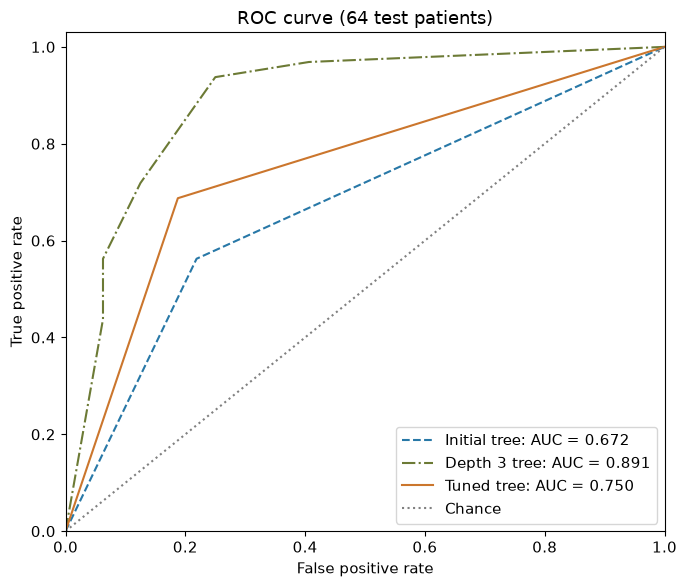

In [19]:
fig, ax = plt.subplots(figsize=(7, 6)) # lager en figur til ROC-kurvene
for name, color, style in zip(models, COLORS, ["--", "-.", "-"]): # gir hver modell egen farge og linjestil
    fpr, tpr, _ = metrics.roc_curve(y_test == 0, probabilities[name]) # beregner feildiagnoser og treff ved ulike grenser
    auc = results.loc[name, "ROC-AUC"] # henter AUC-resultatet fra tabellen
    ax.plot(fpr, tpr, color=color, linestyle=style, label=f"{name}: AUC = {auc:.3f}") # tegner modellens ROC-kurve
ax.plot([0, 1], [0, 1], ":", color="grey", label="Chance") # tegner referansen for tilfeldig rangering
ax.set(title="ROC curve (64 test patients)", xlabel="False positive rate", # setter tittel og x-akse
       ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.03)) # setter y-akse og aksenes grenser
ax.legend() # viser hvilken kurve som tilhører hver modell
plt.tight_layout() # tilpasser avstanden rundt figuren
plt.show() # viser ROC-kurvene

### Visualizing tuned tree

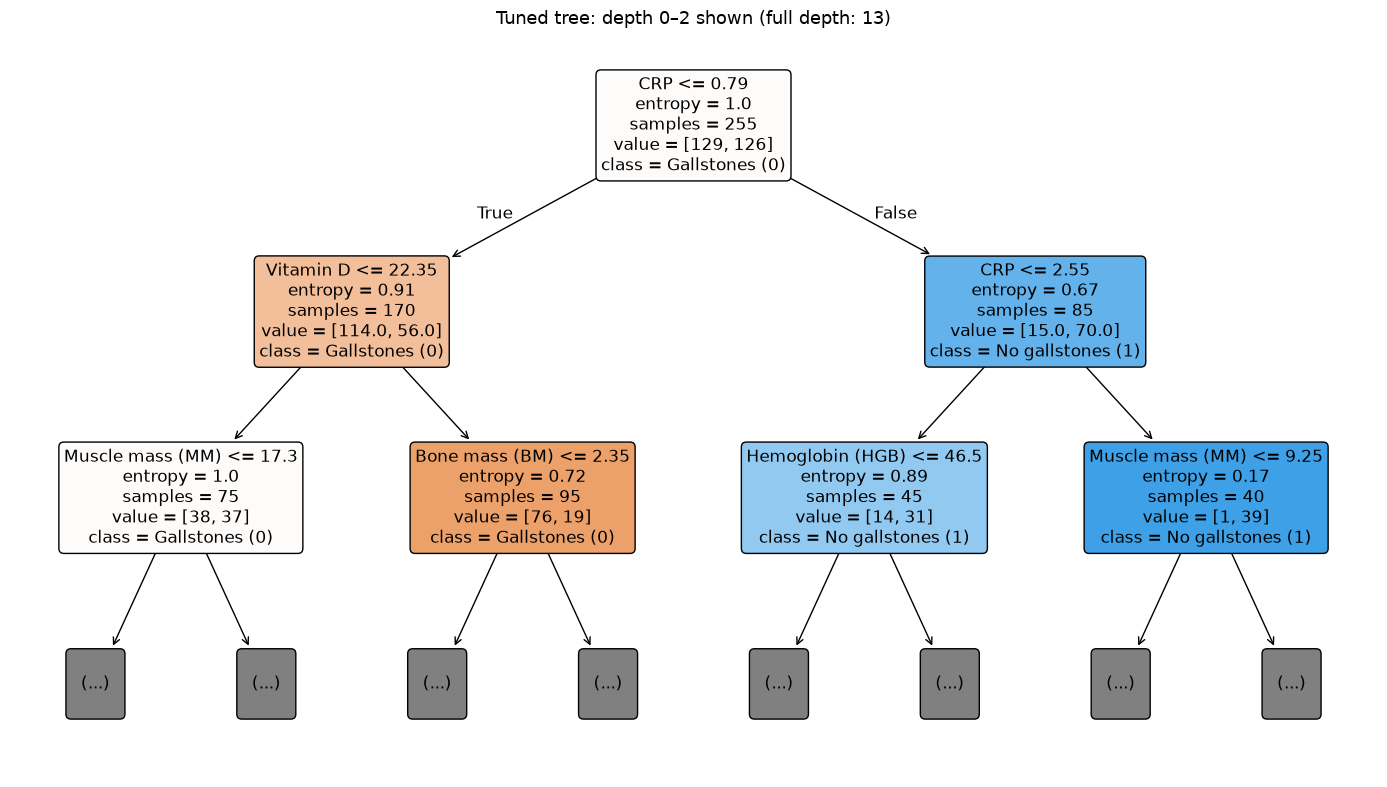

In [17]:
plot_labels = ["Vitamin D", "CRP", "Body fat (TBFR, %)", "Bone mass (BM)", "Muscle mass (MM)", "Hemoglobin (HGB)"] # lager korte navn til grafene
fig, ax = plt.subplots(figsize=(14, 8)) # lager en stor figur til treet
tree.plot_tree(best_tree, feature_names=plot_labels, class_names=CLASS_NAMES, # bruker riktige variabel- og klassenavn
               filled=True, rounded=True, max_depth=2, precision=2, fontsize=12, ax=ax) # viser de øverste nivåene
ax.set_title(f"Tuned tree: depth 0–2 shown (full depth: {best_tree.get_depth()})") # oppgir treets virkelige dybde
plt.tight_layout() # gir boksene og tittelen plass
plt.show() # viser treet med lærte regler

### Tree depth and overfitting

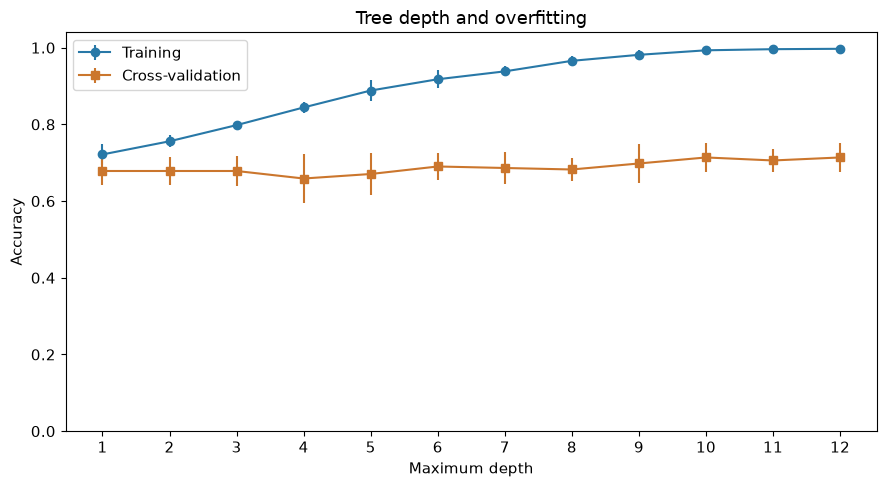

In [18]:
depths = np.arange(1, 13) # velger dybdene 1 til og med 12
depth_train, depth_cv = ms.validation_curve( # måler resultatene ved ulike maksimale dybder.
    decision_tree, X_train, y_train, param_name="max_depth", # endrer bare dybden til startmodellen.
    param_range=depths, cv=cv, scoring="accuracy" # måler nøyaktighet med de samme fem foldene.
)
fig, ax = plt.subplots() # lager figuren
ax.errorbar(depths, depth_train.mean(axis=1), yerr=depth_train.std(axis=1), # beregner snitt og spredning for trening
            color=COLORS[0], fmt="o-", label="Training") # tegner treningskurven med runde punkter
ax.errorbar(depths, depth_cv.mean(axis=1), yerr=depth_cv.std(axis=1), # beregner snitt og spredning for validering
            color=COLORS[2], fmt="s-", label="Cross-validation") # tegner valideringskurven med firkanter
ax.set(title="Tree depth and overfitting", xlabel="Maximum depth", ylabel="Accuracy", # navngir grafen og aksene
       ylim=(0, 1.04), xticks=depths) # bruker en skala fra null og viser hver dybde
ax.legend() # forklarer de to kurvene
plt.tight_layout() # sørger for at teksten får plass
plt.show() # viser hvordan dybden påvirker resultatene

### Prints results

In [12]:
testOut = pd.DataFrame({"Actual": y_test, "Predicted": predictions["Tuned tree"]}) # samler fasit og modellens svar
testOut.head(10) # viser de ti første testpasientene

,Actual,Predicted
310,1,1
130,0,0
245,1,1
144,0,1
26,0,0
239,1,1
175,1,1
126,0,1
99,0,0
247,1,1


## Conclusion (before cleansed data)
- tuning improves test accuracy from 67.2% to 75.0%
- the depth-3 tree scores 79.7% on this test set. Tuning follows training CV, not test ranking
- the tuned tree finds 22 of 32 gallstone cases, but still overfits (100% training accuracy)

### References

Decision Tree: https://scikit-learn.org/stable/modules/tree.html

Grid Search: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html